Radiation vs time of day

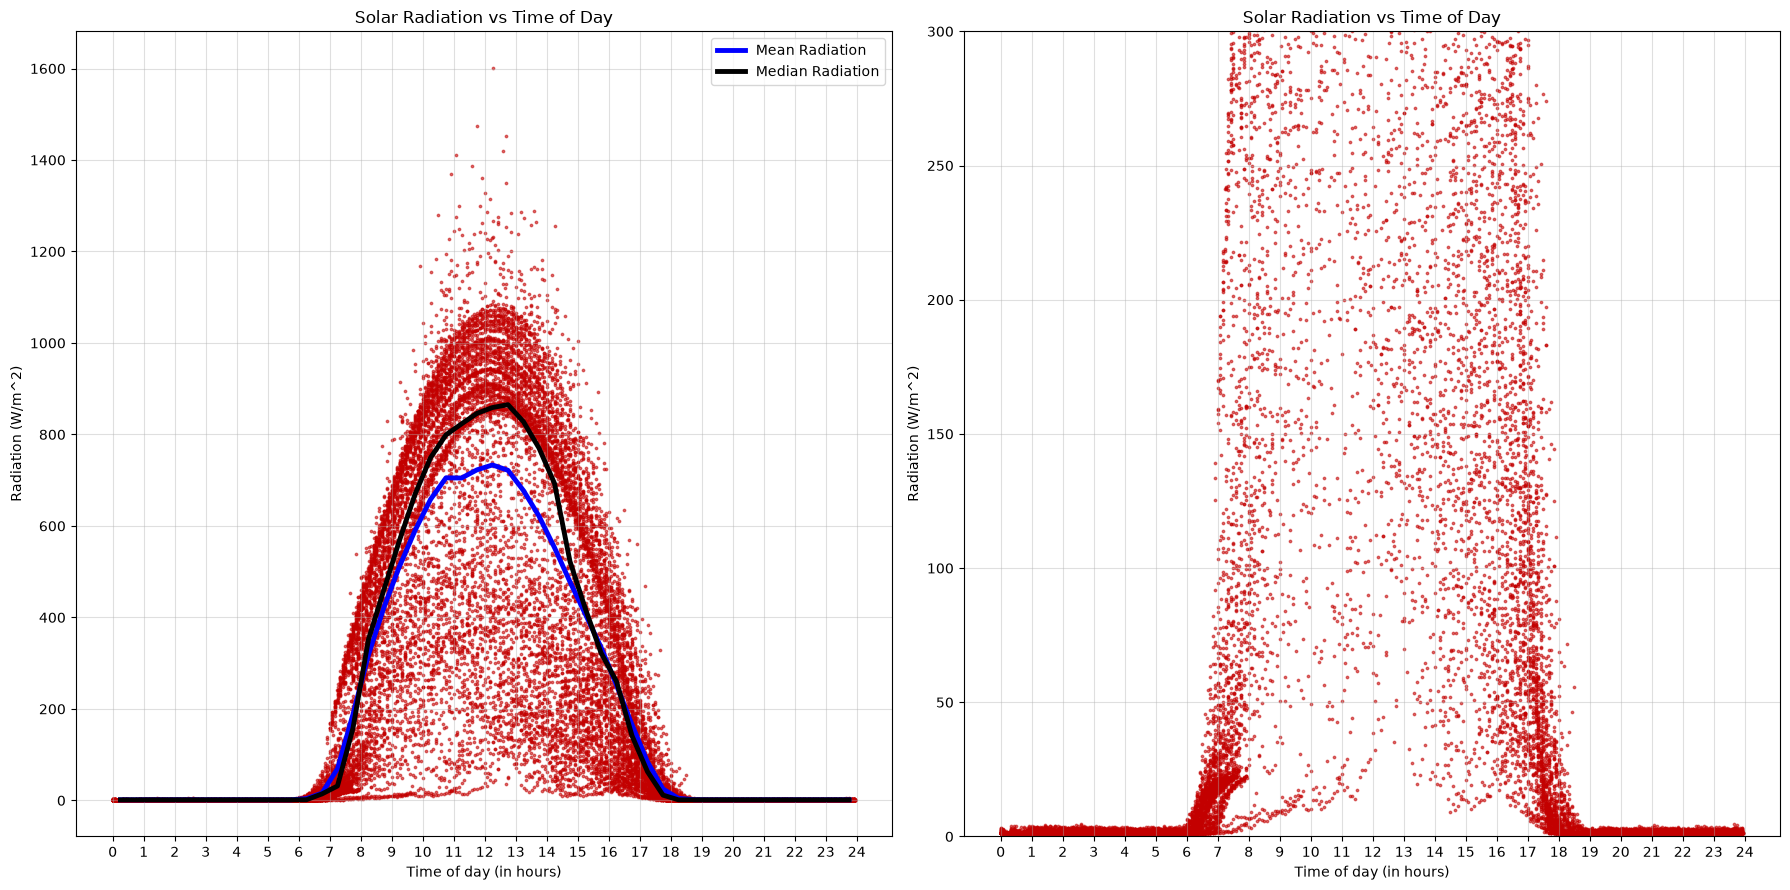

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df=pd.read_csv('../solar_radiation_data/SolarPrediction.csv')

time_hr=[]

for value in df['Time']:
    parts=value.split(':')
    hour=int(parts[0])
    minute=int(parts[1])
    second=int(parts[2])
    time_hr.append(hour+minute/60+second/3600)

df['Time_hr']=time_hr

x=df['Time_hr']
y=df['Radiation']

fig, ax = plt.subplots(1,2,figsize=(18, 9))

ax[0].scatter(x, y, s=3, alpha=0.55,color='#c30000')
ax[0].set_xticks(np.arange(0, 25, 1))
ax[0].set_xlabel('Time of day (in hours)')
ax[0].set_ylabel('Radiation (W/m^2)')
ax[0].set_title('Solar Radiation vs Time of Day')
ax[0].grid(True,alpha=0.4)

ax[1].scatter(x, y, s=3, alpha=0.55,color='#c30000')
ax[1].set_xticks(np.arange(0, 25, 1))
ax[1].set_xlabel('Time of day (in hours)')
ax[1].set_ylabel('Radiation (W/m^2)')
ax[1].set_title('Solar Radiation vs Time of Day')
ax[1].set_ylim(0,300)
ax[1].grid(True,alpha=0.4)

slice_width=0.5
sliced_time_hr=[]
for value in df['Time_hr']:
    slice=np.floor(value/slice_width)*slice_width
    sliced_time_hr.append(slice)

df['Sliced_Time_hr']=sliced_time_hr

result = df.groupby('Sliced_Time_hr')['Radiation'].agg(['mean', 'median'])
result=result.reset_index()

ax[0].plot(result['Sliced_Time_hr']+slice_width/2, result['mean'], color='blue', label='Mean Radiation', linewidth=3.5)
ax[0].plot(result['Sliced_Time_hr']+slice_width/2, result['median'], color='black', label='Median Radiation', linewidth=3.5)
ax[0].legend(loc='upper right')


fig.tight_layout()

fig.savefig('../plots/solar_radiation_vs_time.png', dpi=300, bbox_inches='tight')
plt.show()

Radiation vs temp and Radiation vs hummidity with same plot analysis

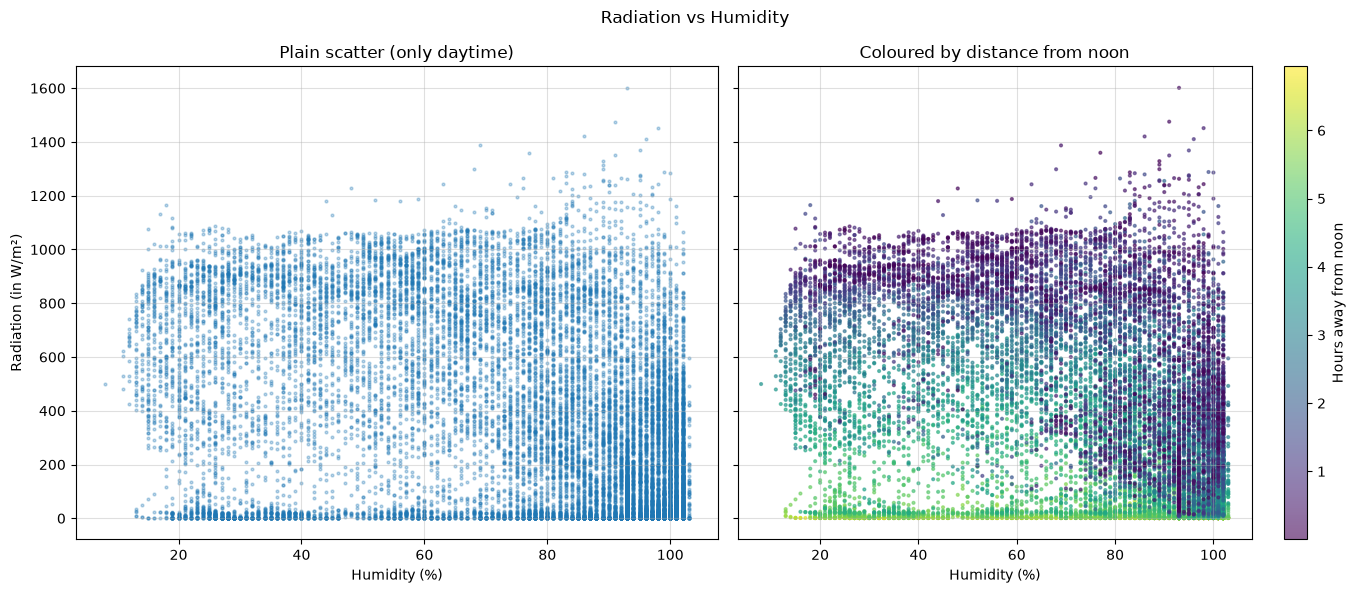

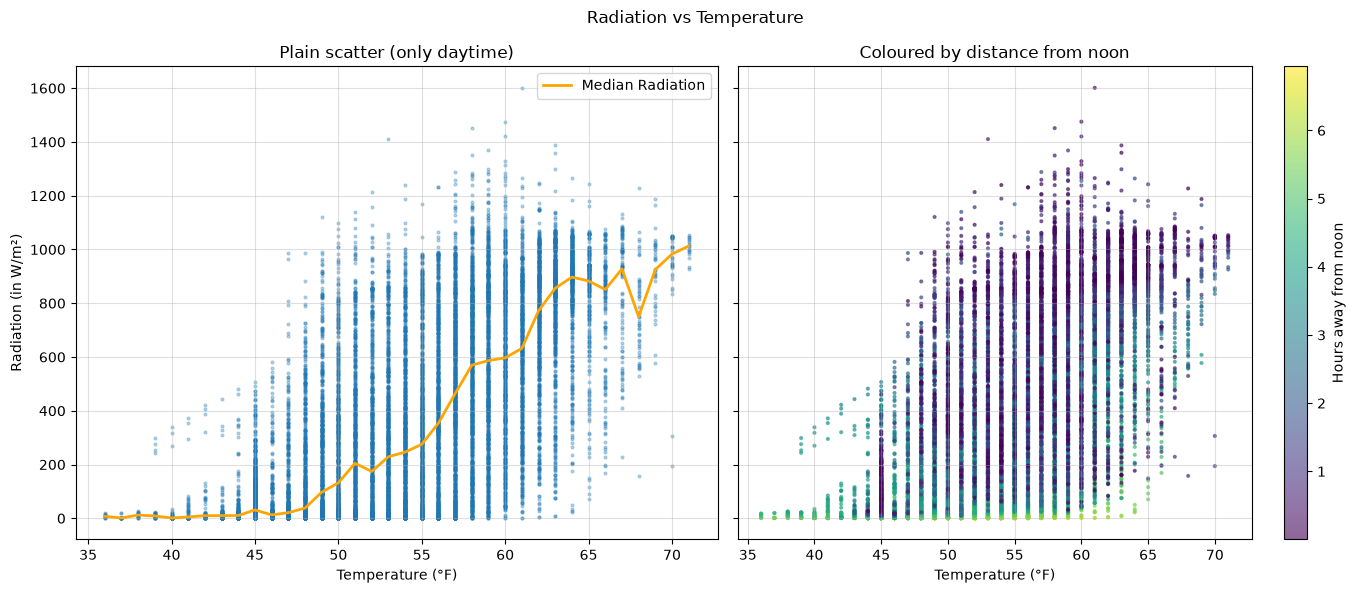

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../solar_radiation_data/SolarPrediction.csv')

time_hr=[]

for value in df['Time']:
    parts=value.split(':')
    hour=int(parts[0])
    minute=int(parts[1])
    second=int(parts[2])
    time_hr.append(hour+minute/60+second/3600)

df['Time_hr']=time_hr

df['from_noon'] = (df['Time_hr'] - 12).abs()

# day time from 6 am to 7 pm
day = df[(df['Time_hr'] >= 6) & (df['Time_hr'] <= 19)]


def plot_vs(data, col, xlabel, fname, add_plot=False):
    # draw far-from-noon points first so midday points sit on top
    d = data.sort_values('from_noon', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

    # left: plain scatter
    axes[0].scatter(d[col], d['Radiation'], s=4, alpha=0.3)

    if add_plot:
        temp_median=day.groupby('Temperature')['Radiation'].agg(['median','count']).reset_index()
        axes[0].plot(temp_median['Temperature'], temp_median['median'], color='orange', label='Median Radiation', linewidth=2)
        axes[0].legend(loc='upper right')
    
    axes[0].set_title('Plain scatter (only daytime)')
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel('Radiation (in W/m²)')
    axes[0].grid(alpha=0.4)

    # right: coloured by distance from noon
    sc = axes[1].scatter(d[col], d['Radiation'], c=d['from_noon'],
                         cmap='viridis', s=4, alpha=0.6)
    fig.colorbar(sc, ax=axes[1], label='Hours away from noon')
    axes[1].set_title('Coloured by distance from noon')
    axes[1].set_xlabel(xlabel)
    axes[1].grid(alpha=0.4)

    fig.suptitle(f'Radiation vs {col}')
    
    plt.tight_layout()
    
    fig.savefig(fname, dpi=150)
    plt.show()


plot_vs(day, 'Humidity', 'Humidity (%)', '../plots/radiation_vs_humidity_day.png')
plot_vs(day, 'Temperature', 'Temperature (°F)', '../plots/radiation_vs_temperature_day.png',add_plot=True)

